# Tomorrow's electricity demand: let the worst days say what is missing

**Three rounds of "run it, look at which days went wrong, fix that" cut the average miss of a day-ahead forecast from 345 to 223 megawatts. The days still wrong after that all point at something the data does not contain.**

Every evening a grid operator needs tomorrow's demand, half-hour by half-hour. We start with the rule everyone starts with, "the same as yesterday", and improve it without a single new algorithm. Each round, TimeGym runs the forecast for 337 days and keeps every one, so we can ask which days it got wrong. The answer names the next fix: first the weekday, then the public holidays, and finally the weather, which is where this data stops.

*Data: half-hourly electricity demand in Victoria, Australia, for 2014, from the Monash Time Series Forecasting Archive, CC BY 4.0 ([source and license](data/README.md#electricity-demand)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import Pipeline, SeasonalLastValueForecaster, cases_from_series

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

## The demand

One value per half-hour, in gigawatts, 48 a day. Three weeks are enough to see the two rhythms a forecast has to follow: the shape of a day, and a week in which Saturday and Sunday are lower.

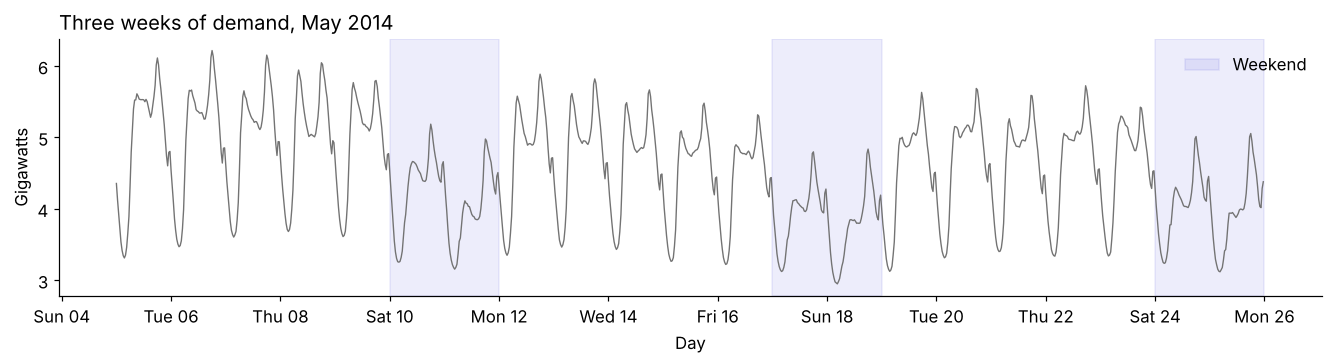

17,520 half-hours, 01 January 2014 to 31 December 2014. Average demand 4.61 gigawatts.


In [2]:
demand = load("electricity-demand")
megawatts = 1000   # the data is in gigawatts; we report misses in megawatts

fig, ax = plt.subplots(figsize=(12, 3.2), layout="constrained")
weeks = demand.loc["2014-05-05":"2014-05-25", "demand"]
ax.plot(weeks.index, weeks, color="0.45", linewidth=0.9)
for saturday in pd.date_range("2014-05-10", "2014-05-24", freq="7D"):
    ax.axvspan(saturday, saturday + pd.Timedelta(days=2), color="#0000CC", alpha=0.07,
               label="Weekend" if saturday.day == 10 else None)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
ax.set(title="Three weeks of demand, May 2014", xlabel="Day", ylabel="Gigawatts")
ax.legend(loc="upper right")
plt.show()
print(f"{len(demand):,} half-hours, {demand.index[0]:%d %B %Y} to {demand.index[-1]:%d %B %Y}. "
      f"Average demand {demand['demand'].mean():.2f} gigawatts.")

## Round one: the same as yesterday

`cases_from_series` cuts the forecasts to make: at each midnight from 29 January on, the history up to that moment and the 48 half-hours of the coming day. That is 337 days. `SeasonalLastValueForecaster(period=48)` repeats the value from 48 half-hours earlier, which is "the same time yesterday".

We add one metric of our own, the average miss as a percentage of the day's demand, because a percentage is what gets quoted for a demand forecast.

In [3]:
horizon = 48
first = 28 * 48   # four weeks of history before the first forecast
cases = cases_from_series(demand, origins=range(first, len(demand) - horizon + 1, 48), horizon=horizon, name="demand")
day = pd.DatetimeIndex([case.observed.index[0] for case in cases])


def percent_miss(observed, predicted):
    observed, predicted = np.asarray(observed, dtype=float), np.asarray(predicted, dtype=float)
    return 100 * np.abs(observed - predicted).mean() / observed.mean()


def test(model):
    "Run a forecaster on every day and return the run with its average miss for each day, in megawatts."
    run = Pipeline(model).run(cases=cases, metrics={"percent_miss": percent_miss}, keep_data=True)
    run.report.assert_passed()   # stop here if any forecast has the wrong dates or shape
    miss = pd.Series([megawatts * entry.metrics["mae"] for entry in run.cases], index=day)
    return run, miss


runs, misses = {}, {}
runs["Same time yesterday"], misses["Same time yesterday"] = test(SeasonalLastValueForecaster(period=48))


def summary():
    return pd.DataFrame({name: {
        "Average miss (megawatts)": misses[name].mean(),
        "Average miss (% of demand)": np.mean([entry.metrics["percent_miss"] for entry in runs[name].cases]),
    } for name in runs}).T


display(summary().round({"Average miss (megawatts)": 0, "Average miss (% of demand)": 1}))
print(f"{len(cases)} days forecast, {horizon} half-hours each.")
by_weekday = misses["Same time yesterday"].groupby(day.day_of_week).mean().set_axis(WEEKDAYS)
display(by_weekday.round(0).astype(int).to_frame("Average miss (megawatts)").T)
assert by_weekday["Mon"] > 2.5 * by_weekday[["Tue", "Wed", "Thu", "Fri"]].mean()
assert by_weekday["Sat"] > 2 * by_weekday[["Tue", "Wed", "Thu", "Fri"]].mean()

,Average miss (megawatts),Average miss (% of demand)
Same time yesterday,345.0,7.6


337 days forecast, 48 half-hours each.


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
Average miss (megawatts),733,231,220,174,219,565,273


The rule misses by 345 megawatts on average, 7.6% of demand. Split by the day being forecast, the miss is between 170 and 270 megawatts from Tuesday to Friday and on Sunday, 565 on Saturdays and 733 on Mondays.

Once seen it is obvious: Monday's forecast is a copy of Sunday, and Saturday's a copy of Friday. The average hid two bad days a week behind five good ones.

## Round two: the right day to copy

Two fixes suggest themselves. "The same time last week" copies the same weekday, seven days back, and is one argument away: `period=336`. The other is a forecaster of our own, **Same kind of day**: for each half-hour, the average over the last four days of the same kind, working days for a working day and weekend days for a weekend day.

It can be written because of how TimeGym calls a model. `fit` receives the history, and `predict` receives the dates to forecast. The model may use anything about those dates, such as the day of the week, and has no way to see the demand on them.

,Average miss (megawatts),Average miss (% of demand)
Same time yesterday,345.0,7.6
Same time last week,283.0,6.2
Same kind of day,239.0,5.3


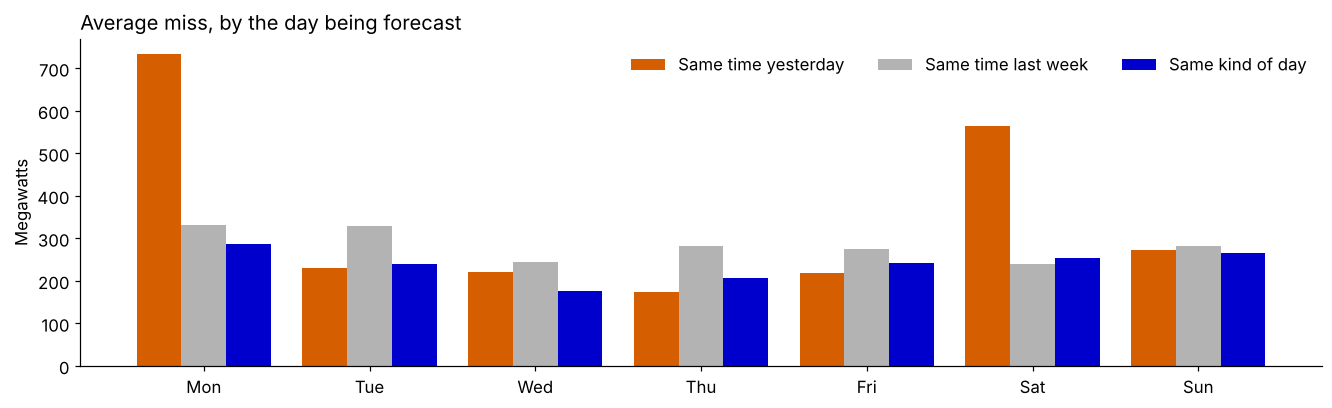

In [4]:
class SameKindOfDay:
    "Each half-hour is the average of that half-hour over the last `days` days of the same kind."

    def __init__(self, days=4, holidays=()):
        self.days = days
        self.holidays = pd.DatetimeIndex(holidays)

    def day_off(self, days):
        "True for weekend days and listed holidays."
        return (days.day_of_week >= 5) | days.isin(self.holidays)

    def fit(self, history):
        # The history starts at midnight and holds whole days, so it folds into one row per day.
        self.past_days_ = np.asarray(history, dtype=float).reshape(-1, 48)
        self.past_off_ = self.day_off(history.index[::48])
        return self

    def predict(self, dates):
        coming_off = self.day_off(dates[::48])
        shapes = [self.past_days_[self.past_off_ == off][-self.days:].mean(axis=0) for off in coming_off]
        return np.concatenate(shapes)[:len(dates)]


runs["Same time last week"], misses["Same time last week"] = test(SeasonalLastValueForecaster(period=336))
runs["Same kind of day"], misses["Same kind of day"] = test(SameKindOfDay(days=4))
display(summary().round({"Average miss (megawatts)": 0, "Average miss (% of demand)": 1}))

weekday_table = pd.DataFrame({name: miss.groupby(day.day_of_week).mean() for name, miss in misses.items()}).set_axis(WEEKDAYS)
colors = {"Same time yesterday": "#D55E00", "Same time last week": "0.7", "Same kind of day": "#0000CC"}
fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
x = np.arange(7)
for position, (name, color) in enumerate(colors.items()):
    ax.bar(x + 0.27 * (position - 1), weekday_table[name], width=0.27, color=color, label=name)
ax.set(title="Average miss, by the day being forecast", ylabel="Megawatts", xticks=x, xticklabels=WEEKDAYS)
ax.legend(loc="upper right", ncols=3)
plt.show()

averages = summary()["Average miss (megawatts)"]
assert averages["Same kind of day"] < averages["Same time last week"] < averages["Same time yesterday"]
assert weekday_table["Same kind of day"].max() < 1.7 * weekday_table["Same kind of day"].min()

Both fixes flatten the week. "Last week" brings the average miss down to 283 megawatts and "same kind of day" to 239, about 5% of demand. Averaging four days does better than copying one, because a single odd day is no longer copied whole.

One detail is worth keeping in mind. From Tuesday to Friday, plain "yesterday" is still as good as either fix, or better. Yesterday carries something that an average over several days loses, and we meet it again at the end.

Otherwise the weekday chart has nothing more to say: every day now misses by a similar amount. So we ask a different question of the same run.

## Round three: the worst days

Which ten days did the best forecaster get most wrong?

In [5]:
def worst(name, count=10):
    days = misses[name].nlargest(count)
    return pd.DataFrame({"Day": days.index.strftime("%a %d %b"), "Average miss (megawatts)": days.round(0).astype(int).to_numpy()},
                        index=pd.RangeIndex(1, count + 1, name="Rank"))


display(worst("Same kind of day").T)

Rank,1,2,3,4,5,6,7,8,9,10
Day,Sun 16 Feb,Sun 02 Feb,Sat 08 Feb,Sat 01 Feb,Sun 09 Feb,Thu 25 Dec,Sat 15 Feb,Sat 22 Feb,Fri 18 Apr,Fri 26 Dec
Average miss (megawatts),1530,1387,1150,1017,985,949,859,826,789,740


Three of the ten are dates anyone would recognize: Christmas Day, Boxing Day and Good Friday. They fell on a Thursday and two Fridays, so the forecaster treated them as working days, and nobody went to work. The other seven are weekend days in February, which we come back to.

The fix for the first group is a list. Victoria had eleven public holidays in 2014. `SameKindOfDay` already takes a `holidays` argument and counts those dates as days off, both when it looks back and when it forecasts.

,Average miss (megawatts),Average miss (% of demand)
Same time yesterday,345.0,7.6
Same time last week,283.0,6.2
Same kind of day,239.0,5.3
"Same kind of day, with holidays",223.0,4.9


,The 9 holidays forecast,The day after each,All other days
Average miss (megawatts),,,
Same kind of day,570,326,228
"Same kind of day, with holidays",266,188,223


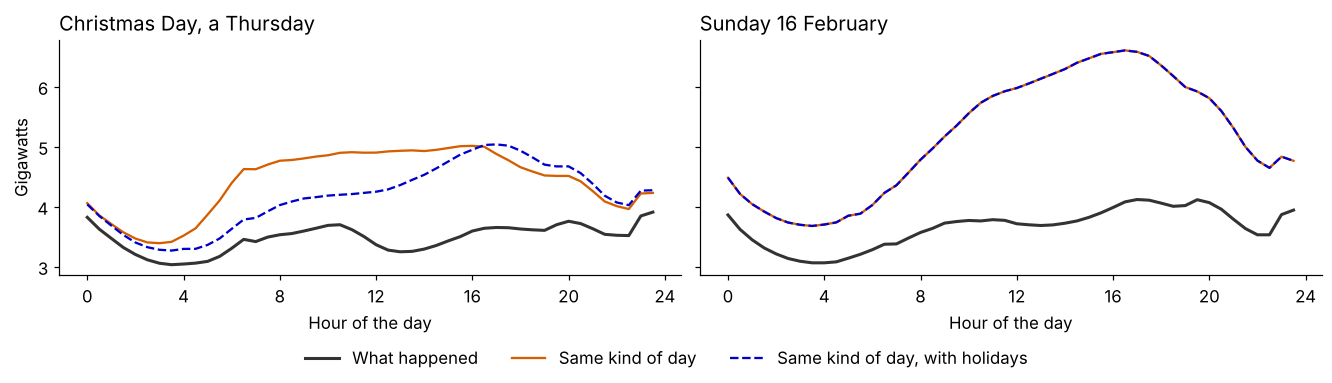

Rank,1,2,3,4,5,6,7,8,9,10
Day,Sun 16 Feb,Sun 02 Feb,Sun 09 Feb,Sat 01 Feb,Sat 08 Feb,Sat 15 Feb,Sat 22 Feb,Tue 04 Mar,Mon 03 Feb,Tue 04 Feb
Average miss (megawatts),1530,1162,1096,962,895,859,826,734,725,725


In [6]:
HOLIDAYS = ["2014-01-01", "2014-01-27", "2014-03-10", "2014-04-18", "2014-04-19", "2014-04-21",
            "2014-04-25", "2014-06-09", "2014-11-04", "2014-12-25", "2014-12-26"]
name = "Same kind of day, with holidays"
runs[name], misses[name] = test(SameKindOfDay(days=4, holidays=HOLIDAYS))
display(summary().round({"Average miss (megawatts)": 0, "Average miss (% of demand)": 1}))

holiday = day.isin(pd.DatetimeIndex(HOLIDAYS))
after_holiday = np.roll(holiday, 1)
effect = pd.DataFrame({label: {"Same kind of day": misses["Same kind of day"][chosen].mean(),
                               name: misses[name][chosen].mean()}
                       for label, chosen in ((f"The {holiday.sum()} holidays forecast", holiday),
                                             ("The day after each", after_holiday),
                                             ("All other days", ~(holiday | after_holiday)))})
display(effect.round(0).astype(int).rename_axis("Average miss (megawatts)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True, layout="constrained")
hours = np.arange(48) / 2
for ax, date, title in ((axes[0], "2014-12-25", "Christmas Day, a Thursday"), (axes[1], "2014-02-16", "Sunday 16 February")):
    index = day.get_loc(pd.Timestamp(date))
    ax.plot(hours, cases[index].observed["demand"], color="0.2", linewidth=2, label="What happened")
    ax.plot(hours, runs["Same kind of day"].cases[index].forecast.point[:, 0], color="#D55E00", label="Same kind of day")
    ax.plot(hours, runs[name].cases[index].forecast.point[:, 0], color="#0000CC", linestyle="--", label=name)
    ax.set(title=title, xlabel="Hour of the day", xticks=range(0, 25, 4))
axes[0].set_ylabel("Gigawatts")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=3)
plt.show()
display(worst(name).T)

assert effect.loc[name].iloc[0] < 0.5 * effect.loc["Same kind of day"].iloc[0]
assert effect.loc[name].iloc[1] < 0.7 * effect.loc["Same kind of day"].iloc[1]
assert misses[name].mean() < misses["Same kind of day"].mean()
february_weekend = [d.month == 2 and d.day_of_week >= 5 for d in misses[name].nlargest(10).index]
assert sum(february_weekend) >= 6

On the nine holidays in the test, the miss falls by more than half, from 570 megawatts to 266. The day after each holiday improves too, from 326 to 188, because the forecaster no longer averages a holiday into its picture of a working day. All other days change little, and the average is down to 223 megawatts.

The left panel shows the repair on Christmas Day. It is partial: the forecast now starts from a weekend's shape, and Christmas is quieter than an ordinary weekend. The right panel shows what a list of dates cannot repair at all.

## What is left: the weather

Seven of the worst ten days are still weekend days in February, and on the worst of them, Sunday 16 February, the forecast is far too high all day. The forecaster averaged the four weekend days before it, and those had much higher demand, peaking in the late afternoon. In an Australian summer that is what air conditioning in a hot spell looks like: several hot weekends, then a mild one. It would also explain why "yesterday" held its own from Tuesday to Friday: yesterday's weather is the best guide to today's that this data has.

We cannot confirm it from here, because the data has no temperature. That is also where this approach ends. A TimeGym model is handed the past of the series and the dates to forecast. There is no place to hand it tomorrow's weather forecast, so a model that needs one cannot be tested this way yet. For this job that is the next thing to add, and no amount of tuning the forecaster above will stand in for it.

## What TimeGym added

- A day-ahead test on 337 days in one line, with every forecaster run on the same days.
- Every forecast kept, with its date. "Which weekday?" and "which ten days?" were questions to a run we already had, and each answer named the next fix.
- A model that is handed the dates to forecast and nothing else about them. The calendar could be used freely, with no way to peek at the demand.
- A gate on every run: `assert_passed()` stops as soon as a forecast has the wrong dates or shape, which matters for a model that folds its history into days.

## Change one thing

- Average more or fewer days: `SameKindOfDay(days=2, holidays=HOLIDAYS)`. Does it matter?
- Forecast two days ahead with `horizon=96`; the model already handles a forecast that spans several days.
- Add a scaled error that compares with "the same time last week": `metrics={"scaled": partial(mase, seasonality=336)}`, with `mase` from `timegym.metrics` and `partial` from `functools`.
- Treat Saturday and Sunday as different kinds of day and see whether the weekend bars come down.

**What this doesn't show.** One year of data from one region, with eleven holidays, nine of them in the test. No temperature, so the largest remaining errors are explained by reasoning, not shown. The source does not say how the clock change for daylight saving was handled. The scorecard was left out on purpose: its seasonal row repeats every 12 steps, which says little about a day of 48 half-hours.

**Related:** [Custom model](../tutorials/02_custom_model.ipynb) for the `fit` and `predict` a model needs, [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) for cutting cases from your own series, and [The model never sees the future](../docs/concepts/scope.md#the-model-never-sees-the-future). More examples are on the [examples page](../docs/examples.md).